# Test neighborhood-level approach:

Note that the method below uses distances in latent space and so is not graph-based anymore

## Prep:

load modules:

In [1]:
%load_ext lab_black

In [2]:
import scanpy as sc
import numpy as np
import pandas as pd
import random
import os
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import kstest
from statsmodels.stats.multitest import multipletests

set paths. change dir_res to your liking

In [3]:
path_hlca_ext = "/lustre/groups/ml01/workspace/hlca_lisa.sikkema_malte.luecken/HLCA_reproducibility/data/d10_1101_2022_03_10_483747/HLCA_v1.1_full.h5ad"
dir_res = "../res/neighborhood_based/"

load files. Below we load the final cellxgene file which is compressed and therefore takes a long time to load... @mariam @daniele you guys probably use a lighter version, so feel free to update path above

In [5]:
adata_ext_full = sc.read_h5ad(path_hlca_ext, backed="r")

set parameters:

In [125]:
k = 5000 # still unclear how high to set this

## Analysis:

For exploration, subset to a single cell type (specify matching annotation level as well). Eventually, we should do this on the entire embedding.

In [7]:
ct1 = "Fibroblast lineage"  # AT2: level 3; DC2: level 4; Dendritic cells: level 3; Fibroblast lineage: level 2
ct1_level = 2

#### Query healthy:

(We should probably adapt and do healthy and disease at the same time, just separate results at the end)

In [58]:
query_dataset = "Sheppard_2020"

In [59]:
adata_ext_h = (
    adata_ext_full[
        [
            (ref_ann == ct1 or ext_ann == ct1)
            and (c_or_e == "core" or (cond == "Healthy" and ds == query_dataset))
            for ref_ann, ext_ann, c_or_e, cond, ds in zip(
                adata_ext_full.obs[f"ann_level_{ct1_level}"],
                adata_ext_full.obs[f"transf_ann_level_{ct1_level}_label"],
                adata_ext_full.obs.core_or_extension,
                adata_ext_full.obs.lung_condition,
                adata_ext_full.obs.dataset,
            )
        ],
        :,
    ]
    .to_memory()
    .copy()
)

subset to random set of cells in graph (TO DO: this could ultimately be done more sophisticatedly, check out e.g. Milo or smart subsampling methods. I wouldn't make that a priority for now, we can do during revisions). Not sure yet what fraction is a good number, now taking 1/500 of cells

In [126]:
n_cells = adata_ext_h.shape[0]
print(f"Number of {ct1} cells:", n_cells)
n_cells_to_sample = round(n_cells / 500)
print(f"Sample {n_cells_to_sample} cells")

Number of Fibroblast lineage cells: 34990
Sample 70 cells


In [127]:
cell_subset_idc = random.sample(range(n_cells), k=n_cells_to_sample)
cell_subset_barcodes = adata_ext_h.obs.iloc[cell_subset_idc, :].index

recalculate neighbor graph. Note: this takes veeeeery long now, we should probably only calculate distances of the set of subsampled cells to all other cells, that might be faster (unless scanpy has optimized the hell out of this and we cannot equal that with standard packages). Consider using https://docs.scipy.org/doc/scipy/reference/generated/scipy.spatial.distance.cdist.html. Make sure to use the embeddding to calculate distances!

Also not tried yet: method="rapids". You need gpu for this, and the documentation says it's experimental I think...

In [128]:
sc.pp.neighbors(adata_ext_h, use_rep="X_scanvi_emb", n_neighbors=k)  # method="gauss"

visualize index cells in umap:

In [129]:
sc.tl.umap(adata_ext_h)

In [130]:
adata_ext_h.obs["cell_sampled"] = "no"
adata_ext_h.obs.loc[cell_subset_barcodes, "cell_sampled"] = "yes"

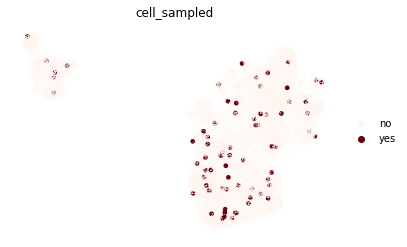

In [230]:
dotsize = 3
sc.pl.umap(
    adata_ext_h,
    color="cell_sampled",
    frameon=False,
    size=[
        30 * dotsize if sampled == "yes" else dotsize
        for sampled in adata_ext_h.obs.cell_sampled
    ],
    palette="Reds",
)

Some further info visualized:

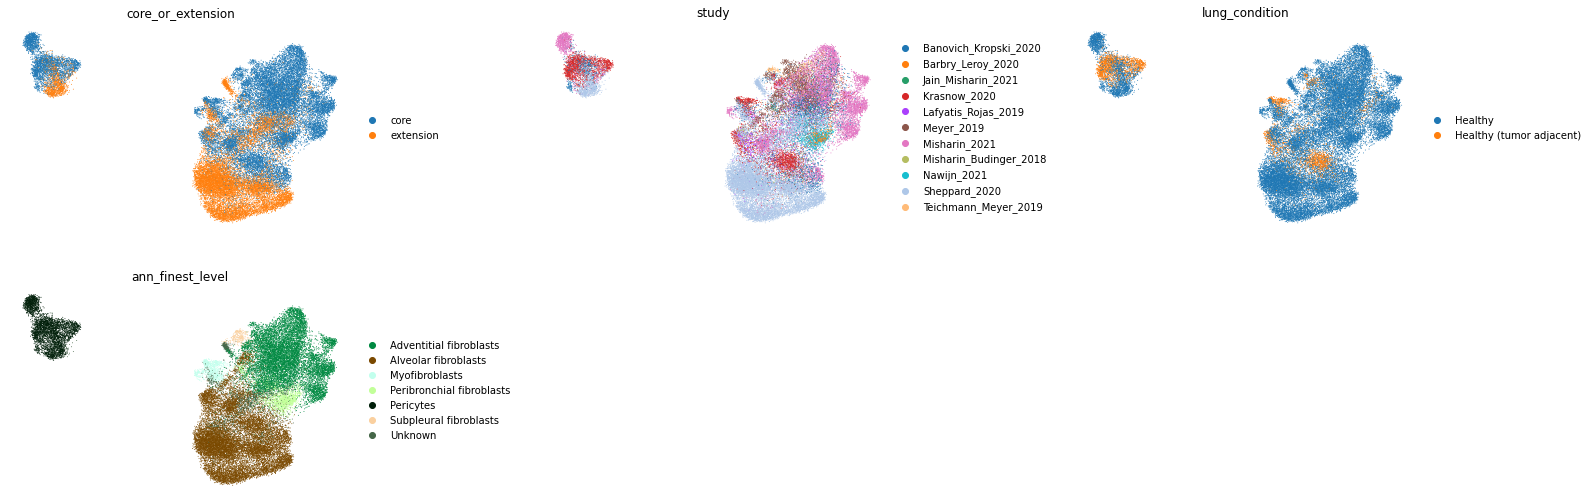

In [237]:
sc.pl.umap(
    adata_ext_h,
    color=["core_or_extension", "study", "lung_condition", "ann_finest_level"],
    frameon=False,
    ncols=3,
    wspace=0.4,
)

calculate distances for (previously selected) random subset of neighborhoods with index cells from reference<br>

In [137]:
dist_ext_subset = adata_ext_h.obsp["distances"][cell_subset_idc, :]

check which cells are the neighbors:

Note that distances are only stored for the k-1 cells with the lowest distances, all others are set to 0. (Also: connectivities are stored for a larger subset, likely because connectivities are symmetrized and therefore rank differently). Thus, by taking the k-1 highest distances, we get the distances for the k-1 cells closest to a given cell. (For some reason scanpy stores distances and connectivities for k-1 nearest neighbors/cells (I guess the neighborhood, including index cell, is then k?), so we'll take the top k-1 cells for each cell.)

In [238]:
def get_highest_column_numbers(matrix, n):
    sorted_indices = np.argsort(matrix, axis=1)[:, ::-1]
    highest_columns = sorted_indices[:, :n]
    return highest_columns

In [138]:
neighbors_idc = get_highest_column_numbers(dist_ext_subset.toarray(), k - 1)

now subset the distance matrix to only the nearest neighbors:

In [139]:
neighbors_distances = dist_ext_subset[
    np.arange(n_cells_to_sample)[:, np.newaxis],
    neighbors_idc,
].toarray()

for each neighbor, get the name of its sample of origin:

In [140]:
neighbors_samples = np.array(adata_ext_h.obs["sample"].values)[
    neighbors_idc
]

calculate mean distance to index cell per sample:

In [141]:
def mean_per_row_group(matrix, grouping):
    unique_groups = np.unique(grouping)
    means_per_group = np.zeros((matrix.shape[0], unique_groups.shape[0]))

    for group_number, group in enumerate(unique_groups):
        mask = grouping == group
        group_sum = np.nansum(matrix * mask, axis=1)
        group_count = np.nansum(mask, axis=1)
        mean_per_row = group_sum / group_count
        means_per_group[:, group_number] = mean_per_row
    return unique_groups, means_per_group

In [142]:
samples_ext, means_per_sample_ext = mean_per_row_group(
    neighbors_distances, neighbors_samples
)

/home/icb/lisa.sikkema/miniconda3/envs/HLCA_basic/lib/python3.7/site-packages/ipykernel_launcher.py:11: RuntimeWarning: invalid value encountered in true_divide
  # This is added back by InteractiveShellApp.init_path()


store results in pandas dataframe:

In [149]:
res_healthy = pd.DataFrame(
    data=means_per_sample_ext.T, index=samples_ext, columns=cell_subset_barcodes
)

##### query disease:

In [ ]:
# ...to do, probably just include from the start above

#### Results healthy:

(Code below is maybe not the most efficient, but it's nothing memory-heavy so only need to change if it's confusing to you)

In [150]:
res_healthy.shape

(128, 70)

prepare dataframe for split boxplot (we need two columns rather than a dataframe with rowsxcolumns)

In [155]:
res_healthy_flat = res_healthy.unstack()
res_healthy_flat = pd.DataFrame(res_healthy_flat)
res_healthy_flat.reset_index(level=1, inplace=True)
res_healthy_flat.rename(
    columns={"level_1": "sample", 0: "mean_distance_to_index_cell"}, inplace=True
)
res_healthy_flat["neighborhood"] = res_healthy_flat.index
res_healthy_flat["index_cell_origin"] = adata_ext_h.obs.loc[
    res_healthy_flat.neighborhood, "core_or_extension"
]
res_healthy_flat["neighborhood, cell type, ref or q"] = [
    f"{nh}, {adata_ext_h.obs.loc[nh,'ann_finest_level']} ({adata_ext_h.obs.loc[nh,'core_or_extension']})"
    for nh in res_healthy_flat.neighborhood
]
res_healthy_flat["ref_or_q"] = "ref"
q_samples = adata_ext_h.obs.loc[
    adata_ext_h.obs.core_or_extension == "extension", "sample"
].unique()
res_healthy_flat.loc[res_healthy_flat["sample"].isin(q_samples), "ref_or_q"] = "q"

Now plot:

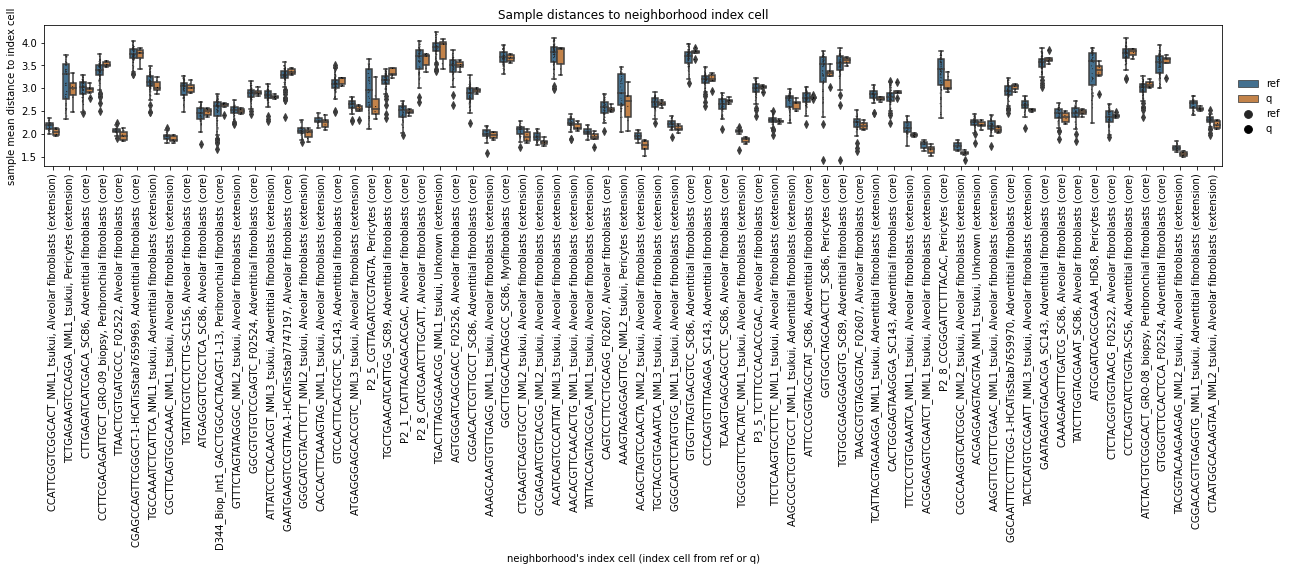

In [239]:
fig, ax = plt.subplots(figsize=(18, 8))
sns.boxplot(
    data=res_healthy_flat,
    x="neighborhood, cell type, ref or q",
    y="mean_distance_to_index_cell",
    ax=ax,
    hue="ref_or_q",
    saturation=0.5,
)
sns.stripplot(
    data=res_healthy_flat,
    x="neighborhood, cell type, ref or q",
    y="mean_distance_to_index_cell",
    ax=ax,
    hue="ref_or_q",
    dodge=True,
    size=1,
    color="black",
)
ax.tick_params(axis="x", rotation=90)
leg = plt.legend(loc=(1.01, 0.2), frameon=False, title="")
leg._legend_box.align = "left"
ax.set_xlabel("neighborhood's index cell (index cell from ref or q)")
ax.set_ylabel("sample mean distance to index cell")
ax.set_title("Sample distances to neighborhood index cell")
plt.tight_layout()
plt.show()

Perform KS-test for every neighborhood.<br>
First, prepare empty dataframe:

In [183]:
neighborhood_stats = pd.DataFrame(
    index=cell_subset_barcodes, columns=["KS_stat", "pvalue"]
)

Now calculate stats:

In [241]:
# loop through neighborhoods
for index_cell in cell_subset_barcodes:
    # check if index cell is from query or ref
    index_source = adata_ext_h.obs.loc[index_cell, "core_or_extension"]
    # extract mean distances from query samples to index cell.
    # drop nas, i.e. ignore samples not observed in the neighborhood
    query_sample_results = res_healthy_flat.loc[
        [
            nh == index_cell and ref_or_q == "q"
            for nh, ref_or_q in zip(
                res_healthy_flat.neighborhood, res_healthy_flat.ref_or_q
            )
        ],
        "mean_distance_to_index_cell",
    ].dropna()
    # get same results for reference samples
    ref_sample_results = res_healthy_flat.loc[
        [
            nh == index_cell and ref_or_q == "ref"
            for nh, ref_or_q in zip(
                res_healthy_flat.neighborhood, res_healthy_flat.ref_or_q
            )
        ],
        "mean_distance_to_index_cell",
    ].dropna()
    # test one-sided, query greater than reference for neighborhoods with ref
    # index cells. Store results in dataframe
    if index_source == "core":
        # test if query distances are larger than reference:
        neighborhood_stats.loc[index_cell, :] = kstest(
            rvs=ref_sample_results.values,
            cdf=query_sample_results.values,
            alternative="greater",
        )
    # test one-sided, but now query smaller than reference for neighborhoods
    # with query index cells. Store results in dataframe
    elif index_source == "extension":
        # test if query distances are larger than reference:
        neighborhood_stats.loc[index_cell, :] = kstest(
            rvs=ref_sample_results.values,
            cdf=query_sample_results.values,
            alternative="less",
        )

Perform multiple testing correcting (benjamini-hochberg FDR):

In [194]:
neighborhood_stats["pvalue_corr"] = multipletests(
    neighborhood_stats.pvalue.values, method="fdr_bh"
)[1]

Add KS test results to adata_ext_h for visualization, and add some further information (binary significant/not significant, and -log10 pvalues)

In [225]:
adata_ext_h.obs["KS_test_corr_pvals"] = 1
adata_ext_h.obs.loc[
    neighborhood_stats.index, "KS_test_corr_pvals"
] = neighborhood_stats.pvalue_corr
adata_ext_h.obs["KS_test_sign"] = (adata_ext_h.obs.KS_test_corr_pvals < 0.05).astype(
    float
)
adata_ext_h.obs["-log10(KS_test_corr_pvals)"] = -np.log10(
    adata_ext_h.obs.KS_test_corr_pvals.astype(float)
)

Now visualize results (put sampled cells at the end of the anndata (i.e. lowest rows) to make the visualization cleaner, with big dots=index cells on top)

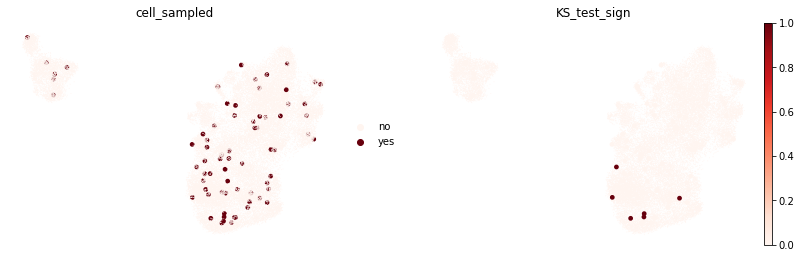

In [245]:
dotsize = 3
sc.pl.umap(
    adata_ext_h,
    color=["cell_sampled", "KS_test_sign"],
    frameon=False,
    size=[
        30 * dotsize if sampled == "yes" else dotsize
        for sampled in adata_ext_h.obs.cell_sampled
    ],
    cmap="Reds",
    palette="Reds",
)

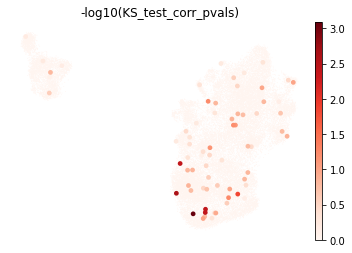

In [227]:
sc.pl.umap(
    adata_ext_h,
    color=["-log10(KS_test_corr_pvals)"],
    frameon=False,
    size=[
        30 * dotsize if sampled == "yes" else dotsize
        for sampled in adata_ext_h.obs.cell_sampled
    ],
    cmap="Reds",
    palette="Reds",
)

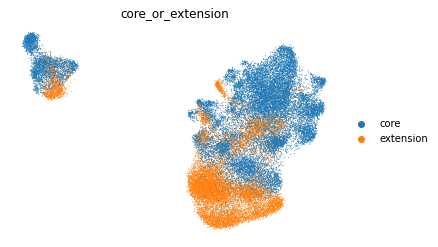

In [206]:
sc.pl.umap(adata_ext_h, color="core_or_extension", frameon=False)

#### Store results:

In [243]:
ct1_no_spaces = ct1.replace(" ", "_")
file_prefix = f"{ct1_no_spaces}_{query_dataset}_k{k}_healthy"
res_healthy.to_csv(os.path.join(dir_res, file_prefix + "_distances.csv"))
fig.savefig(
    os.path.join(dir_res, file_prefix + "_boxplot.png"), bbox_inches="tight", dpi=140
)